# Taller: Redes neuronales con scikit-learn
### Clasificación desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus compañeros antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo → Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## 📑 Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 📥 Le damos datos (bien preparados).
- 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [210]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo! 🎉")

¡Todo listo! 🎉


---
# Parte 3 · Clasificación con `MLPClassifier`

Ya conocemos el flujo. Ahora lo vamos a aplicar a **clasificación**, donde en vez de predecir un número, predecimos una **categoría**. Vas a ver que el código es muy parecido.

## El problema: ¿de qué especie es este pingüino?

Usaremos el dataset público **Palmer Penguins**: medidas de pingüinos de tres especies (*Adelie*, *Chinstrap* y *Gentoo*) de las islas del archipiélago Palmer, en la Antártida.

> **Variable objetivo (categórica):** `species` → problema de **clasificación multiclase** (3 clases).

In [211]:
url_pinguinos = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_ping = pd.read_csv(url_pinguinos)

print(f"Dimensiones: {df_ping.shape}")
df_ping.head()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [212]:
# Valores faltantes y distribución de las clases
print("Valores faltantes por columna:")
print(df_ping.isna().sum())

print("\nDistribución de especies:")
print(df_ping["species"].value_counts())

Valores faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Distribución de especies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


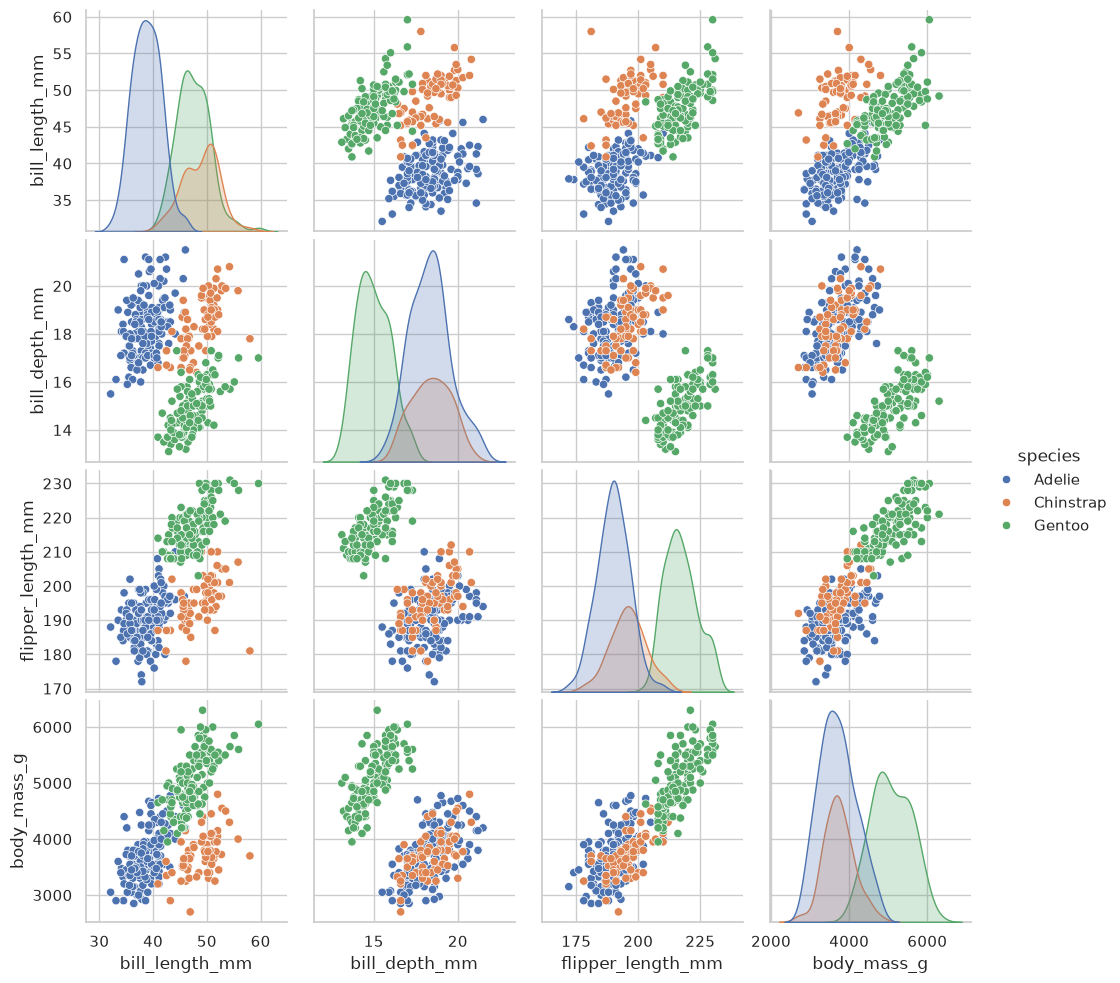

In [213]:
# Relación entre variables, coloreando por especie
sns.pairplot(df_ping, hue="species", vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
plt.show()

### 🤔 Para pensar
- ¿Qué pares de variables separan mejor las tres especies?
- ¿Cuánta dificultad esperás que tenga este problema para un clasificador?

- Creo que las combinaciones de "bill_length" con "bill_depth" y "flipper_length" son las que mejor permiten diferenciar las especies.
- Se ve en los graficos que las especies presentan diferencias bastante claras en sus medidas, por lo tanto, espero que el clasificador no tenga mucha dificultad.

## Paso 1 · Preparación y división de datos

Igual que antes, pero con dos diferencias:

- Las variables categóricas (`island`, `sex`) también tienen faltantes, así que las imputamos con la **moda** (`most_frequent`).
- Al dividir usamos **`stratify=y`**: así entrenamiento y prueba mantienen **la misma proporción de cada especie**. Es muy recomendable en clasificación.

In [214]:
X_p = df_ping.drop(columns=["species"])
y_p = df_ping["species"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

Proporción de clases en entrenamiento:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64


In [215]:
cols_num_p = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cols_cat_p = ["island", "sex"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

## Paso 2 · Baselines y primera red neuronal

Comparamos:
- **Dummy**: siempre predice la clase más frecuente.
- **Regresión logística**: clasificador lineal simple.
- **MLP**: nuestra red neuronal.

In [216]:
# Función para evaluar clasificadores
def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

# Baseline 1: Dummy
dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

# Baseline 2: Regresión logística
logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

# Nuestra primera red neuronal para clasificar
mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

pd.DataFrame(resultados_clf)

,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
0,Dummy (clase mayoritaria),0.444,0.435,0.202
1,Regresión logística,0.993,1.000,1.000
2,"MLP inicial (32,16)",1.000,0.986,0.983


### ¿Cómo leer las métricas de clasificación?

- **Accuracy (exactitud)**: proporción de aciertos totales. Es intuitiva, pero puede engañar si las clases están desbalanceadas.
- **F1 macro**: promedia el F1 (balance entre precisión y sensibilidad) de cada clase **dándoles el mismo peso**. Es más justa cuando hay clases minoritarias.
- Compará siempre contra el **Dummy**: nos dice el "piso" que hay que superar.

### 🤔 Para pensar



¿ por qué es importante considerar otras métricas además del Accuracy?

- Porque el accuracy puede resultar engañoso cuando las clases están desbalanceadas. El F1 macro permite evaluar el rendimiento de forma más equilibrada, ya que considera la precisión de cada clase por igual.

## Paso 3 · Analizar resultados de clasificación

### Reporte por clase y matriz de confusión

- El **reporte de clasificación** muestra precisión, sensibilidad (*recall*) y F1 **para cada clase**.
- La **matriz de confusión** muestra qué clases se confunden entre sí: filas = clase real, columnas = clase predicha. Lo ideal es que solo la diagonal tenga valores.

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



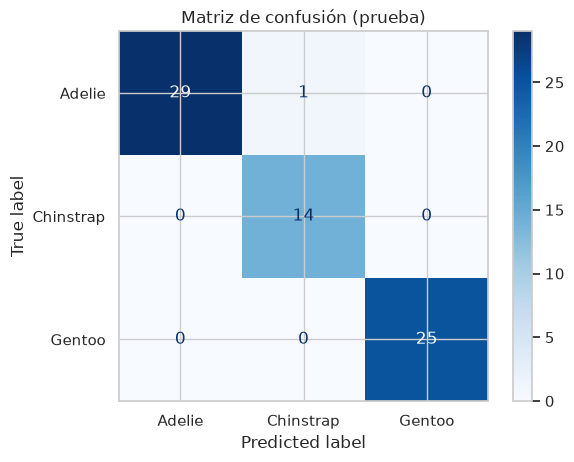

In [217]:
pred_p = mlp_clf.predict(X_prueba_p)

print(classification_report(y_prueba_p, pred_p))

ConfusionMatrixDisplay.from_estimator(mlp_clf, X_prueba_p, y_prueba_p, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

### Probabilidades de cada clase

Un `MLPClassifier` no solo dice "esta es la clase X": también nos da **la probabilidad estimada de cada clase** con `predict_proba`. Esto es muy útil para saber **qué tan seguro** está el modelo.

In [218]:
# Probabilidades para los primeros 5 pingüinos de prueba
probabilidades = pd.DataFrame(
    mlp_clf.predict_proba(X_prueba_p.head()),
    columns=mlp_clf.classes_           # los nombres de las clases
)
probabilidades["predicha"] = mlp_clf.predict(X_prueba_p.head())
probabilidades["real"] = y_prueba_p.head().values
probabilidades.round(3)

,Adelie,Chinstrap,Gentoo,predicha,real
0,0.984,0.012,0.004,Adelie,Adelie
1,0.999,0.001,0.000,Adelie,Adelie
2,0.003,0.001,0.996,Gentoo,Gentoo
3,0.001,0.000,0.999,Gentoo,Gentoo
4,0.007,0.993,0.000,Chinstrap,Chinstrap


In [219]:
# ¿Dónde se equivoca el modelo? Miramos los casos mal clasificados
errores = X_prueba_p.copy()
errores["real"] = y_prueba_p
errores["predicha"] = pred_p
errores[errores["real"] != errores["predicha"]]

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,real,predicha
37,Dream,42.2,18.5,180.0,3550.0,FEMALE,Adelie,Chinstrap


### 🤔 Para pensar
- ¿Qué tan difícil resultó este problema? ¿Cuánto mejora la red respecto de la regresión logística?
- Si el modelo casi no se equivoca, ¿cuánto margen de mejora nos queda para el ajuste de hiperparámetros?

- El problema resultó relativamente sencillo para ambos modelos. Pero la regresión logística obtuvo mejores resultados que la red neuronal, alcanzando un accuracy del 100% frente al 98,6% del MLP.
- Ambos modelos ya tienen un rendimiento muy alto, queda poco margen de mejora. Por eso, ajustar los hiperparámetros probablemente no produzca cambios significativos.

## Paso 4 · Ajuste de hiperparámetros con `RandomizedSearchCV`

Cuando hay **muchos hiperparámetros**, una grilla completa se vuelve enorme. `RandomizedSearchCV` es una alternativa: en vez de probar todas las combinaciones, **sortea `n_iter` combinaciones al azar** de las distribuciones que le indicamos. Suele encontrar buenas configuraciones con mucho menos costo.

Para parámetros continuos como `alpha` usamos `loguniform`: sortea valores en escala logarítmica (tiene sentido porque nos interesa probar 0.0001, 0.001, 0.01..., no solo valores entre 0 y 1).

Además usamos **`StratifiedKFold`** para que cada partición de la validación cruzada conserve las proporciones de clases, y optimizamos **`f1_macro`**.

In [220]:
# Distribuciones / listas de valores a explorar
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),                # entre 0.00001 y 1
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),  # (solo afecta al solver "adam")
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                  # cantidad de combinaciones aleatorias a probar
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=SEMILLA,
    verbose=1
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid module name: 'sklearn.exceptions'
Invalid -W option ignored: invalid


Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 2.8381292701126715e-05
  mlp__hidden_layer_sizes: (64, 32)
  mlp__learning_rate_init: 0.0003972110727381913
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.997


In [221]:
res_c = pd.DataFrame(busqueda_clf.cv_results_)
columnas_c = ["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__solver",
              "param_mlp__alpha", "mean_test_score", "std_test_score", "rank_test_score"]

res_c.sort_values("rank_test_score")[columnas_c].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__solver,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
6,"(64, 32)",tanh,adam,2.838e-05,0.997,0.006,1
7,"(32,)",relu,adam,1.707e-05,0.997,0.006,1
14,"(64, 32)",tanh,adam,4.298e-01,0.997,0.006,1
15,"(32, 16)",tanh,adam,4.233e-04,0.997,0.006,1
12,"(64, 32)",tanh,lbfgs,1.336e-03,0.997,0.006,1
13,"(16,)",relu,lbfgs,7.046e-01,0.997,0.006,1
9,"(32, 16)",tanh,lbfgs,3.335e-04,0.997,0.006,1
16,"(64,)",tanh,adam,6.703e-01,0.997,0.006,1


> 💡 **Observación importante:** en este dataset, muchas configuraciones distintas logran resultados casi idénticos (¡y muy altos!). Cuando el problema es "fácil" y el modelo simple ya rinde muy bien, **ajustar hiperparámetros aporta poco**: las diferencias entre configuraciones quedan dentro del ruido (`std_test_score`). En problemas más difíciles, el ajuste suele marcar más diferencia.

In [222]:
mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")

,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
modelo,,,
Dummy (clase mayoritaria),0.444,0.435,0.202
Regresión logística,0.993,1.000,1.000
"MLP inicial (32,16)",1.000,0.986,0.983
MLP optimizado (RandomSearch),1.000,0.986,0.983


## Paso 5 · ¿Qué variables usa el modelo para decidir?

Repetimos la **importancia por permutación**, ahora con `accuracy` como métrica.

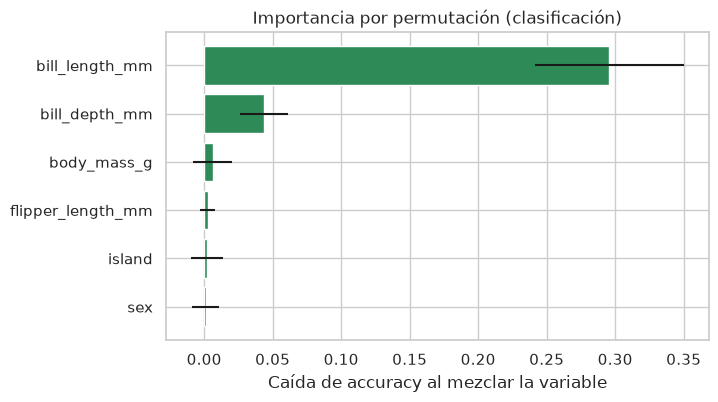

In [223]:
imp_c = permutation_importance(
    mejor_clf, X_prueba_p, y_prueba_p,
    n_repeats=30, scoring="accuracy", random_state=SEMILLA
)

importancias_c = pd.DataFrame({
    "variable": X_prueba_p.columns,
    "caida_accuracy": imp_c.importances_mean,
    "desvio": imp_c.importances_std
}).sort_values("caida_accuracy")

plt.figure(figsize=(7, 4))
plt.barh(importancias_c["variable"], importancias_c["caida_accuracy"], xerr=importancias_c["desvio"], color="seagreen")
plt.xlabel("Caída de accuracy al mezclar la variable")
plt.title("Importancia por permutación (clasificación)")
plt.show()

---
# Parte 4 · Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

>  `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5. Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

---
## Actividad 2 · Clasificación: ¿quién sobrevivió al Titanic?

**Dataset:** `titanic` (público, repositorio de datos de `seaborn`). Cada fila es un pasajero y la variable objetivo es `survived` (1 = sobrevivió, 0 = no sobrevivió).

 **Objetivo:** construir un clasificador binario con una red neuronal, analizar sus errores y ajustar hiperparámetros.

 **Te sirve de guía:** Parte 3 (Clasificación).

Este dataset es **más difícil** que el de pingüinos: tiene más faltantes y no hay una separación tan clara entre clases. ¡Aquí el ajuste y el análisis sí van a importar!

In [224]:
url_titanic = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_tit = pd.read_csv(url_titanic)

df_tit.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.283,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.100,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.050,S,Third,man,True,NaN,Southampton,no,True


**2.1 · Exploración y selección de variables.**

**Cuidado con las "trampas":** el dataset incluye columnas redundantes o que **revelan directamente la respuesta**. Por ejemplo, `alive` contiene "yes"/"no" y es equivalente a `survived`. Usarla como predictora sería un caso de **fuga de información (*data leakage*)**: el modelo tendría un rendimiento espectacular... pero completamente inútil en la vida real.

Otras columnas (`class`, `who`, `adult_male`, `embark_town`, `alone`) repiten información de columnas que ya existen, y `deck` tiene demasiados faltantes.

Trabajá **solo** con estas variables predictoras:

- Numéricas: `pclass`, `age`, `sibsp`, `parch`, `fare`
- Categóricas: `sex`, `embarked`

Explorá: ¿cuál es la proporción de sobrevivientes? ¿Cuántos faltantes tiene cada variable elegida? ¿Cómo cambia la supervivencia según `sex` y `pclass`?

In [225]:
df_tit.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


La variable age presenta 177 valores nulos y embarked solamente 2. Aunque deck también tiene muchos valores faltantes, no la considero porque será eliminada junto con las demás columnas que no se utilizarán.

In [226]:
df_tit = df_tit.drop(columns=["class", "who", "adult_male", "embark_town", "alone", "deck", "alive"])

In [227]:
df_tit.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


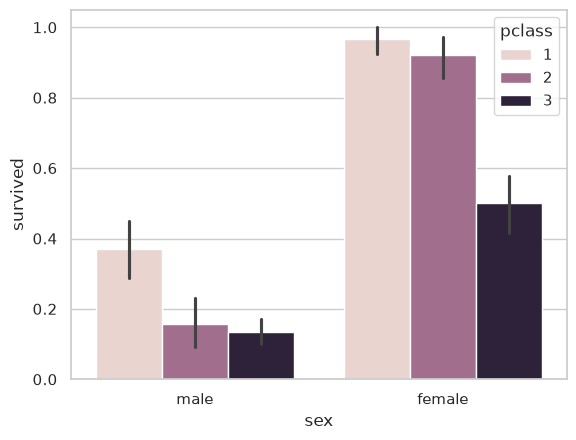

In [228]:
# Tu código aquí
df_tit["survived"].value_counts(normalize=True)

sns.barplot(data=df_tit, x="sex", y="survived", hue="pclass")

plt.show()

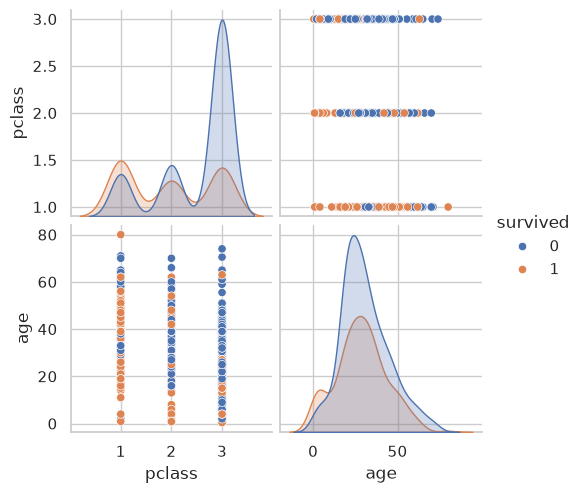

In [229]:
sns.pairplot(df_tit, hue="survived", vars=["pclass", "age"])
plt.show()

**Tu respuesta (2.1):**
- Las variables que parecen tener mayor influencia en la supervivencia son el sexo, la clase del pasajero y la edad. En los gráficos se observa que las mujeres y los pasajeros de primera clase tuvieron mayores probabilidades de sobrevivir. Esto podría relacionarse con la prioridad que recibieron las mujeres durante la evacuación y las diferencias de acceso a los botes salvavidas según la clase.

**2.2 · División y preprocesamiento.**
- Dividí en entrenamiento y prueba (80 / 20) **con `stratify`**.
- Armá un `ColumnTransformer` que, para las numéricas, imputa con la mediana y estandariza; y para las categóricas, imputa con la moda y aplica `OneHotEncoder`.

In [230]:
# Tu código aquí
X_p = df_tit.drop(columns=["survived"])
y_p = df_tit["survived"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

Proporción de clases en entrenamiento:
survived
0    0.617
1    0.383
Name: proportion, dtype: float64


Se observa que aproximadamente el 62% de los pasajeros no sobrevivió, mientras que el 38% sí lo hizo. Al utilizar "stratify", mantenemos estas proporciones en los conjuntos de entrenamiento y prueba, evitando que la división genere diferencias importantes en la distribución de las clases.

In [231]:
cols_num_p = ["pclass", "age", "sibsp", "parch", "fare"]
cols_cat_p = ["sex", "embarked"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

preprocesador_clf

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

**2.3 · Modelos de referencia y primera red neuronal.**
Entrená un `DummyClassifier`, una `LogisticRegression` y un `MLPClassifier` (por ejemplo con `hidden_layer_sizes=(32, 16)`). Compará *accuracy* y *F1 macro* en entrenamiento y prueba usando `evaluar_clasificacion`.

In [232]:
# Función para evaluar clasificadores
def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

# Baseline 1: Dummy
dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

# Baseline 2: Regresión logística
logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

# Nuestra primera red neuronal para clasificar
mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

pd.DataFrame(resultados_clf)

,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
0,Dummy (clase mayoritaria),0.617,0.615,0.381
1,Regresión logística,0.808,0.804,0.786
2,"MLP inicial (32,16)",0.896,0.782,0.767


Logicamente, el Dummy obtuvo el peor rendimiento. La regresión logística y el MLP consiguieron resultados similares en prueba, con un accuracy rondando el 80%. Pero el MLP alcanzó un rendimiento bastante mayor en entrenamiento 90%, lo que podría indicar cierto sobreajuste, ya que esa mejora no se refleja en los datos de prueba.

**2.4 · Análisis de errores.**
Mostrá el reporte de clasificación y la matriz de confusión del MLP. Respondé:
- ¿Se equivoca más al predecir a los que sobrevivieron o a los que no?
- En un problema real, ¿qué tipo de error te parecería más grave? ¿Por qué depende del contexto?

              precision    recall  f1-score   support

           0       0.81      0.85      0.83       110
           1       0.73      0.68      0.71        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179



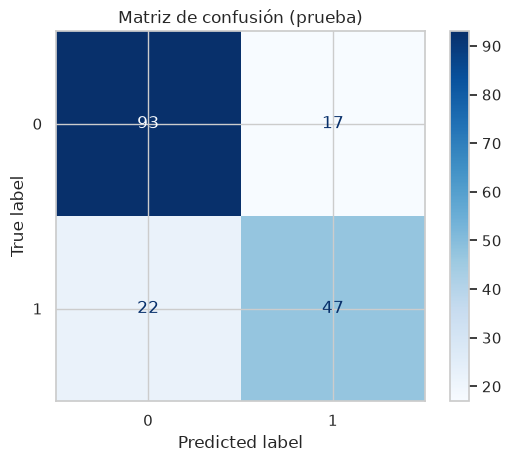

In [233]:
# Tu código aquí
pred_p = mlp_clf.predict(X_prueba_p)

print(classification_report(y_prueba_p, pred_p))

ConfusionMatrixDisplay.from_estimator(mlp_clf, X_prueba_p, y_prueba_p, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

In [234]:
# Probabilidades para los primeros 5 sobrevivientes de prueba
probabilidades = pd.DataFrame(
    mlp_clf.predict_proba(X_prueba_p.head()),
    columns=mlp_clf.classes_           # los nombres de las clases
)
probabilidades["predicha"] = mlp_clf.predict(X_prueba_p.head())
probabilidades["real"] = y_prueba_p.head().values
probabilidades.round(3)

,0,1,predicha,real
0,0.993,0.007,0,0
1,0.999,0.001,0,0
2,0.660,0.340,0,1
3,0.999,0.001,0,0
4,0.000,1.000,1,1


In [235]:
# ¿Dónde se equivoca el modelo? Miramos los casos mal clasificados
errores = X_prueba_p.copy()
errores["real"] = y_prueba_p
errores["predicha"] = pred_p
errores[errores["real"] != errores["predicha"]]

,pclass,sex,age,sibsp,parch,fare,embarked,real,predicha
553,3,male,22.0,0,0,7.225,C,1,0
559,3,female,36.0,1,0,17.400,S,1,0
536,1,male,45.0,0,0,26.550,S,0,1
216,3,female,27.0,0,0,7.925,S,1,0
279,3,female,35.0,1,1,20.250,S,1,0
712,1,male,48.0,1,0,52.000,S,1,0
455,3,male,29.0,0,0,7.896,C,1,0
165,3,male,9.0,0,2,20.525,S,1,0
745,1,male,70.0,1,1,71.000,S,0,1
297,1,female,2.0,1,2,151.550,S,0,1


**Tu respuesta (2.4):**
- Observando la matriz de confusión y el classification_report, se ve que el modelo tiene más dificultades para identificar a los pasajeros que sobrevivieron. Esto se refleja en el recall, que es de 0.68 para los sobrevivientes, frente a 0.85 para los que no sobrevivieron.
- En un problema real, el error más grave dependería de para qué se va a usar el modelo. Si se usara para identificar personas que necesitan ser rescatadas, sería más grave no detectar a alguien que realmente necesita ayuda. En cambio, si los recursos fueran muy limitados, los falsos positivos también podrían generar problemas al destinarlos a personas que no los necesitan.

**2.5 · Ajuste de hiperparámetros.**
Usá `RandomizedSearchCV` con `StratifiedKFold` (5 particiones) y `scoring="f1_macro"` (o `"accuracy"`, si preferís justificar). Explorá al menos `hidden_layer_sizes`, `alpha` y `activation`. Evaluá el mejor modelo en prueba.

Luego respondé: **¿la mejora respecto del MLP inicial es "real" o está dentro del ruido?** (Pista: compará la diferencia con `std_test_score`).

In [236]:
# Distribuciones / listas de valores a explorar
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),                # entre 0.00001 y 1
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),  # (solo afecta al solver "adam")
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                  # cantidad de combinaciones aleatorias a probar
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=SEMILLA,
    verbose=1
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 0.00042330329965275946
  mlp__hidden_layer_sizes: (32, 16)
  mlp__learning_rate_init: 0.0006516990611177178
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.805


In [237]:
res_c = pd.DataFrame(busqueda_clf.cv_results_)
columnas_c = ["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__solver",
              "param_mlp__alpha", "mean_test_score", "std_test_score", "rank_test_score"]

res_c.sort_values("rank_test_score")[columnas_c].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__solver,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
15,"(32, 16)",tanh,adam,4.233e-04,0.805,0.028,1
14,"(64, 32)",tanh,adam,4.298e-01,0.803,0.030,2
1,"(32,)",logistic,adam,1.695e-03,0.801,0.030,3
0,"(32,)",logistic,adam,9.610e-02,0.799,0.030,4
11,"(64,)",logistic,lbfgs,3.520e-01,0.799,0.020,5
13,"(16,)",relu,lbfgs,7.046e-01,0.799,0.028,6
16,"(64,)",tanh,adam,6.703e-01,0.796,0.032,7
17,"(8,)",relu,adam,1.026e-01,0.795,0.017,8


In [238]:
mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")

,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
modelo,,,
Dummy (clase mayoritaria),0.617,0.615,0.381
Regresión logística,0.808,0.804,0.786
"MLP inicial (32,16)",0.896,0.782,0.767
MLP optimizado (RandomSearch),0.872,0.804,0.789


In [239]:
scores_inicial = cross_val_score(
    mlp_clf,
    X_ent_p,
    y_ent_p,
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1
)

print(f"MLP inicial: {scores_inicial.mean():.3f} ± {scores_inicial.std():.3f}")

print(f"MLP optimizado: {busqueda_clf.best_score_:.3f} ± "
      f"{busqueda_clf.cv_results_['std_test_score'][busqueda_clf.best_index_]:.3f}")

MLP inicial: 0.783 ± 0.019
MLP optimizado: 0.805 ± 0.028


**Tu respuesta (2.5):**

El MLP optimizado consiguió mejorar ligeramente al MLP inicial en el conjunto de prueba, aumentando el F1 macro de 0.767 a 0.789 y el accuracy de 78.2% a 80.4%.

Además, presenta una menor diferencia entre el rendimiento de entrenamiento y prueba, lo que podría indicar una reducción del sobreajuste.

En validación cruzada también mejoró, pasando de 0.783 a 0.805. Sin embargo, esta diferencia de 0.022 es pequeña en comparación con las desviaciones estándar (0.019 y 0.028), por lo que no podemos asegurar que la mejora sea consistente y no se deba a la variabilidad de los datos.

**2.6 · Importancia de variables y umbral de decisión.**

**(a)** Calculá la importancia por permutación. ¿Coincide con lo que viste en la exploración?

**(b)** Por defecto, el modelo clasifica como "sobrevivió" si la probabilidad supera **0.5**. Pero podemos elegir otro **umbral**. Con `predict_proba`, calculá la *precisión* y el *recall* de la clase 1 usando umbrales de 0.3, 0.5 y 0.7. ¿Qué ocurre con cada métrica al subir el umbral?

```python
from sklearn.metrics import precision_score, recall_score

probabilidad_sobrevivir = modelo.predict_proba(X_prueba)[:, 1]   # columna de la clase 1
for umbral in [0.3, 0.5, 0.7]:
    pred = (probabilidad_sobrevivir >= umbral).astype(int)
    # calculá precision_score(y_prueba, pred) y recall_score(y_prueba, pred)
```

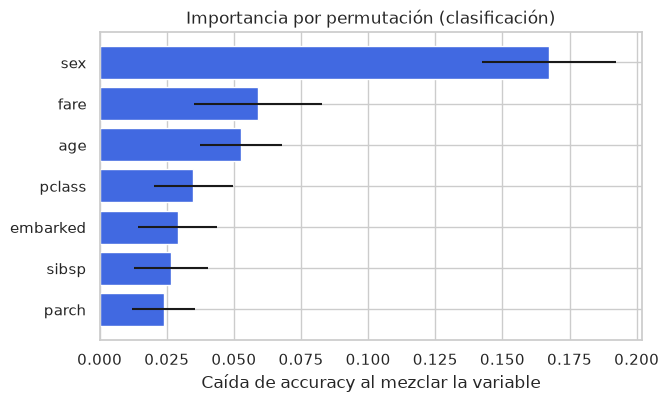

In [240]:
imp_c = permutation_importance(
    mejor_clf, X_prueba_p, y_prueba_p,
    n_repeats=30, scoring="accuracy", random_state=SEMILLA
)

importancias_c = pd.DataFrame({
    "variable": X_prueba_p.columns,
    "caida_accuracy": imp_c.importances_mean,
    "desvio": imp_c.importances_std
}).sort_values("caida_accuracy")

plt.figure(figsize=(7, 4))
plt.barh(importancias_c["variable"], importancias_c["caida_accuracy"], xerr=importancias_c["desvio"], color="royalblue")
plt.xlabel("Caída de accuracy al mezclar la variable")
plt.title("Importancia por permutación (clasificación)")
plt.show()

2.6 a)

Sí, observando el gráfico de importancia por permutación, los resultados coinciden con lo visto durante la exploración inicial. El sexo y la edad del pasajero son variables importantes para el modelo, mientras que la pclass también influye, pero en menor medida.

In [241]:
# Tu código aquí
from sklearn.metrics import precision_score, recall_score

probabilidad_sobrevivir = mejor_clf.predict_proba(X_prueba_p)[:, 1]   # columna de la clase 1
for umbral in [0.3, 0.5, 0.7]:
    pred = (probabilidad_sobrevivir >= umbral).astype(int)

    precision = precision_score(y_prueba_p, pred, zero_division=0)
    recall = recall_score(y_prueba_p, pred, zero_division=0)

    print(f"Umbral: {umbral}")
    print(f"  Precision: {precision:.3f}")
    print(f"  Recall:    {recall:.3f}")
    print(f"-------------------------")

Umbral: 0.3
  Precision: 0.675
  Recall:    0.783
-------------------------
Umbral: 0.5
  Precision: 0.774
  Recall:    0.696
-------------------------
Umbral: 0.7
  Precision: 0.816
  Recall:    0.580
-------------------------


2.6 b)

Al aumentar el umbral de decisión, la precisión mejora de 0.675 a 0.816, mientras que el recall disminuye de 0.783 a 0.580.

Esto ocurre porque el modelo necesita una probabilidad mayor para clasificar a un pasajero como sobreviviente. Por lo tanto, se reducen las predicciones positivas incorrectas, pero también se dejan de identificar más sobrevivientes reales.

---
## Actividad 3 · Curva de validación: sobreajuste vs. subajuste

Usando el modelo de la Actividad 2 (Titanic) y la técnica del **Paso 7.2** de la Parte 2, construí una **curva de validación** para el hiperparámetro **`alpha`** (regularización) con valores como `[1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]`.

Usá `scoring="accuracy"` y graficá el puntaje de entrenamiento y de validación (con el eje X en escala logarítmica).

Respondé:
1. ¿Con qué valores de `alpha` hay **sobreajuste**? ¿Y **subajuste**?
2. ¿Qué valor elegirías? ¿Coincide con el que encontró la búsqueda aleatoria?

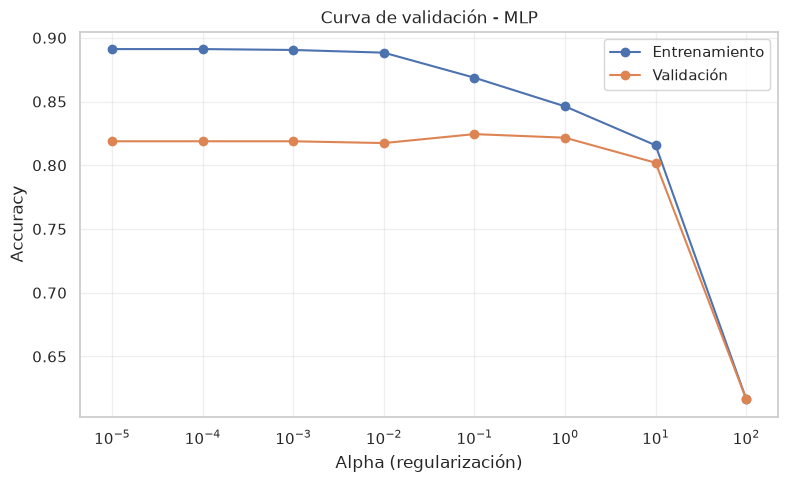

In [242]:
# Tu código aquí
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]

train_scores, valid_scores = validation_curve(
    mejor_clf,
    X_ent_p,
    y_ent_p,
    param_name="mlp__alpha",
    param_range=alphas,
    cv=validacion,
    scoring="accuracy",
    n_jobs=-1
)

# Promedios de las particiones
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)

# Gráfico
plt.figure(figsize=(9, 5))

plt.plot(alphas, train_mean, marker="o", label="Entrenamiento")
plt.plot(alphas, valid_mean, marker="o", label="Validación")

plt.xscale("log")
plt.xlabel("Alpha (regularización)")
plt.ylabel("Accuracy")
plt.title("Curva de validación - MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Tu respuesta (Actividad 3):**

1- Con valores de alpha menores a 1 se aprecia sobreajuste, ya que el accuracy de entrenamiento es bastante mayor que el de validación. En cambio, con alpha = 100 se observa subajuste, porque ambas métricas disminuyen considerablemente.

2- Elegiría alpha = 1 porque es el valor que obtuvo el mayor accuracy en validación y presenta una diferencia relativamente pequeña respecto al entrenamiento. Este resultado no es similar al encontrado por RandomizedSearchCV, que seleccionó un alpha de aproximadamente 0.0004.

---
## Actividad 4 · Reflexión final

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

1. En el dataset de pingüinos el ajuste de hiperparámetros casi no cambió el resultado. ¿Por qué? ¿Cuándo esperarías que el ajuste sí importe mucho?
2. Si tuvieras que explicarle a alguien sin conocimientos técnicos **por qué no basta con mirar el accuracy**, ¿qué ejemplo le darías?

**Tus respuestas:**

1. Porque el problema es relativamente sencillo y los modelos iniciales ya obtienen un rendimiento muy alto, por lo que ajustar los hiperparámetros deja poco margen de mejora. En problemas más complejos, este ajuste podría tener un impacto mayor.
2. El accuracy nos dice cuántas predicciones fueron correctas en total, pero no muestra cómo se distribuyen los errores entre las clases. Por eso, mirar otras métricas como F1 macro permite evaluar el rendimiento de manera más equilibrada y detectar problemas que el accuracy podría ocultar. Por ejemplo, un modelo que siempre predice que los pasajeros no sobrevivieron tendría un accuracy del 62%, pero no identificaría correctamente a ningún sobreviviente.

---
# ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

### Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).